# 05 – Exploratory data analysis

**Goal:** Describe the analysis dataset (pair of consecutive cars × lap) without and with graphics: distributions, missing values, class balance, differences between eras, seasons and circuits, and first relations between the features and the target `overtake`.
**Input:** PostgreSQL tables `pairs`, `races`, `circuits` (notebooks 03 and 04) · **Output:** figures in `reports/figures/eda_*.png`
**Assessment items:** P4 (comprehensive non-graphical and graphical EDA), B3 (circuit geometry from GeoJSON), basis for K4/K6

| Feature | Meaning (all known at the start of lap *n*) |
|---|---|
| `gap_s` | gap of car B to car A at the line (s) |
| `tyre_age_diff` | tyre age B − A (laps); negative = B on fresher tyres |
| `compound_adv` | compound rank B − A (SOFT 3, MEDIUM 2, HARD 1); positive = B on softer tyres |
| `pace_diff` | mean clean lap time of the last 3 laps B − A (s); negative = B faster |
| `quali_gap` | qualifying position B − A; positive = B qualified behind A |
| `position_a` | race position of car A |
| `lap_frac` | lap / race distance |
| `same_team` | both cars from the same team |
| `track_temp`, `air_temp`, `rainfall` | weather at the start of the lap |
| `circuit_type`, `length_km`, `turns`, `longest_straight_m` | circuit (Wikipedia, GeoJSON) |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [2]:
from src.config import ERA_COLORS, ERA_LABELS, SEASONS
from src.db import get_engine
from src.viz import (CIRCUIT_TYPE_COLORS, DIVERGING, SEQUENTIAL, TEXT_SECONDARY,
                     add_source, save, set_style, wilson_ci)

set_style()
engine = get_engine()
SOURCE = (f"FastF1 / Jolpica-F1 / Wikipedia / bacinger f1-circuits, seasons "
          f"{min(SEASONS)}–{max(SEASONS)}, own calculation")

## 1. Analysis dataset (SQL join of three tables)

In [3]:
df = pd.read_sql("""
    SELECT p.*, r.season, r.round, r.era, r.circuit_id,
           c.name AS circuit, c.circuit_type, c.length_km, c.turns, c.longest_straight_m
    FROM pairs p
    JOIN races r    USING (race_id)
    JOIN circuits c USING (circuit_id)
""", engine)
df["season"] = df["season"].astype(int)
NUMERIC = ["gap_s", "tyre_age_diff", "compound_adv", "pace_diff", "quali_gap",
           "position_a", "lap_frac", "track_temp", "air_temp", "length_km", "turns",
           "longest_straight_m"]
print(df.shape)
df.head(3)

(70196, 27)


,pair_id,race_id,lap_number,driver_ahead,driver_behind,position_a,gap_s,tyre_age_diff,compound_adv,wet_tyres,pace_diff,quali_gap,lap_frac,same_team,air_temp,track_temp,rainfall,overtake,season,round,era,circuit_id,circuit,circuit_type,length_km,turns,longest_straight_m
0,1,201801,2,hamilton,raikkonen,1,1.241,NaN,NaN,False,NaN,1.0,0.0345,False,24.2,38.9,False,0,2018,1,E1,albert_park,Albert Park Grand Prix Circuit,street,5.278,16,804.5
1,2,201801,2,raikkonen,vettel,2,0.720,0.0,0.0,False,NaN,1.0,0.0345,True,24.2,38.9,False,0,2018,1,E1,albert_park,Albert Park Grand Prix Circuit,street,5.278,16,804.5
2,3,201801,2,vettel,kevin_magnussen,3,0.913,0.0,0.0,False,NaN,3.0,0.0345,False,24.2,38.9,False,0,2018,1,E1,albert_park,Albert Park Grand Prix Circuit,street,5.278,16,804.5


In [4]:
df.dtypes.to_frame("dtype").T

,pair_id,race_id,lap_number,driver_ahead,driver_behind,position_a,gap_s,tyre_age_diff,compound_adv,wet_tyres,pace_diff,quali_gap,lap_frac,same_team,air_temp,track_temp,rainfall,overtake,season,round,era,circuit_id,circuit,circuit_type,length_km,turns,longest_straight_m
dtype,int64,int64,int64,object,object,int64,float64,float64,float64,bool,float64,float64,float64,bool,float64,float64,bool,int64,int64,int64,object,object,object,object,float64,int64,float64


## 2. Non-graphical EDA

### 2.1 Descriptive statistics

In [5]:
df[NUMERIC].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
gap_s,70196.0,1.047,0.478,0.000,0.664,0.987,1.432,2.000
tyre_age_diff,69627.0,-1.140,7.130,-56.000,-2.000,0.000,0.000,55.000
compound_adv,66762.0,-0.010,0.650,-2.000,0.000,0.000,0.000,2.000
pace_diff,59457.0,-0.049,0.803,-38.678,-0.201,-0.007,0.130,39.291
quali_gap,70016.0,0.369,4.770,-19.000,-2.000,1.000,3.000,19.000
position_a,70196.0,9.770,4.746,1.000,6.000,10.000,13.000,21.000
lap_frac,70196.0,0.418,0.291,0.026,0.155,0.360,0.660,1.000
track_temp,70196.0,36.141,9.209,13.800,29.800,35.700,43.200,57.500
air_temp,70196.0,23.892,4.824,8.900,20.500,23.900,27.300,37.200
length_km,70196.0,5.055,0.822,3.337,4.361,5.278,5.793,7.004


### 2.2 Missing values

In [6]:
missing = df.isna().sum().to_frame("missing")
missing["share_pct"] = (100 * missing["missing"] / len(df)).round(2)
missing.query("missing > 0")

,missing,share_pct
tyre_age_diff,569,0.81
compound_adv,3434,4.89
pace_diff,10739,15.30
quali_gap,180,0.26


- `pace_diff` is missing when fewer than two *clean* laps (no pit stop, no safety car, not lap 1) exist in the three laps before – typically early in the race and right after pit stops or neutralisations.
- `compound_adv` is missing when one car is on intermediate or wet tyres or the compound is unknown.
- `quali_gap` is missing for the few drivers without a qualifying result (e.g. no time set).

Missing values are **not imputed here**; the modelling notebook decides per model (complete cases for the logistic regression, native handling in XGBoost).

### 2.3 Target variable and class balance

In [7]:
counts = df["overtake"].value_counts().rename({0: "no overtake", 1: "overtake"})
pd.DataFrame({"pair_laps": counts, "share_pct": (100 * counts / counts.sum()).round(2)})

,pair_laps,share_pct
overtake,,
no overtake,64734,92.22
overtake,5462,7.78


Only about **8 %** of the pair-laps end with an overtake. A model that always predicts «no overtake» would be 92 % accurate, so accuracy is not a useful metric here; precision, recall and PR-AUC are.

### 2.4 Overtake rate per era and season

In [8]:
by_season = df.groupby(["era", "season"]).agg(
    races=("race_id", "nunique"), pair_laps=("overtake", "size"),
    overtakes=("overtake", "sum"), rate_pct=("overtake", "mean"))
by_season["rate_pct"] = (100 * by_season["rate_pct"]).round(2)
by_season["pair_laps_per_race"] = (by_season["pair_laps"] / by_season["races"]).round(1)
by_season

races  pair_laps  overtakes  rate_pct  pair_laps_per_race
era season                                                           
E1  2018       21       6885        528      7.67               327.9
    2019       21       7183        597      8.31               342.0
    2020       17       6127        445      7.26               360.4
    2021       22       7362        518      7.04               334.6
E2  2022       22       7753        681      8.78               352.4
    2023       22       8831        727      8.23               401.4
    2024       24       9367        695      7.42               390.3
    2025       24      10132        640      6.32               422.2
E3  2026       19       6556        631      9.62               345.1

In [9]:
by_era = df.groupby("era").agg(races=("race_id", "nunique"), pair_laps=("overtake", "size"),
                               overtakes=("overtake", "sum"), rate=("overtake", "mean"))
by_era["rate_pct"] = (100 * by_era.pop("rate")).round(2)
by_era["share_gap_below_0_5s_pct"] = (100 * df.groupby("era")["gap_s"].apply(
    lambda g: (g < 0.5).mean())).round(1)
by_era

,races,pair_laps,overtakes,rate_pct,share_gap_below_0_5s_pct
era,,,,,
E1,81,27557,2088,7.58,8.6
E2,92,36083,2743,7.60,14.7
E3,19,6556,631,9.62,17.1


### 2.5 Era × circuit type (pivot table)

In [10]:
pivot = df.pivot_table(index="circuit_type", columns="era", values="overtake",
                       aggfunc=["mean", "size"])
pivot["mean"] = (100 * pivot["mean"]).round(2)
pivot

mean                size             
era             E1    E2     E3     E1     E2    E3
circuit_type                                       
race          8.35  8.61  10.85  22790  23191  4332
street        3.90  5.79   7.24   4767  12892  2224

### 2.6 Cross tables

In [11]:
pd.crosstab(df["compound_adv"], df["overtake"], normalize="index", margins=True).mul(100).round(1)

overtake,0,1
compound_adv,,
-2.0,87.9,12.1
-1.0,90.6,9.4
0.0,93.4,6.6
1.0,89.8,10.2
2.0,82.4,17.6
All,92.2,7.8


In [12]:
pd.DataFrame({
    "same_team": df.groupby("same_team")["overtake"].agg(["size", "mean"]).stack(),
    "wet_tyres": df.groupby("wet_tyres")["overtake"].agg(["size", "mean"]).stack(),
    "rainfall": df.groupby("rainfall")["overtake"].agg(["size", "mean"]).stack(),
}).round(4)

same_team   wet_tyres    rainfall
False size  62602.0000  67258.0000  67595.0000
      mean      0.0805      0.0781      0.0784
True  size   7594.0000   2938.0000   2601.0000
      mean      0.0560      0.0715      0.0615

### 2.7 Circuits with the highest and lowest overtake rate (at least 3 races)

In [13]:
circuits = df.groupby(["circuit_id", "circuit", "circuit_type"]).agg(
    races=("race_id", "nunique"), pair_laps=("overtake", "size"),
    rate=("overtake", "mean"), longest_straight_m=("longest_straight_m", "first")
).reset_index().query("races >= 3")
circuits["rate_pct"] = (100 * circuits.pop("rate")).round(2)
ranked = circuits.sort_values("rate_pct")
pd.concat({"lowest 10": ranked.head(10).reset_index(drop=True),
           "highest 10": ranked.tail(10)[::-1].reset_index(drop=True)}, axis=1)

lowest 10                                                                                           highest 10                                                                                  \
    circuit_id                         circuit circuit_type races pair_laps longest_straight_m rate_pct  circuit_id                         circuit circuit_type races pair_laps longest_straight_m   
0       monaco               Circuit de Monaco       street     8      4302              274.3     0.95       vegas  Las Vegas Strip Street Circuit       street     3      1050             1246.1   
1   marina_bay       Marina Bay Street Circuit       street     7      2788              532.6     4.91    americas         Circuit of the Americas         race     8      2311             1177.9   
2  albert_park  Albert Park Grand Prix Circuit       street     7      2259              804.5     5.49         spa    Circuit de Spa-Francorchamps         race     9      2210              756.5   
3        imola   Autodromo Enzo e Dino Ferrari         race     5      2036              439.9     5.70     bahrain   Bahrain International Circuit         race     9      3035             1120.9   
4   villeneuve       Circuit Gilles Villeneuve       street     7      3003              685.5     5.96    shanghai  Shanghai International Circuit         race     5      1674             1211.5   
5  silverstone             Silverstone Circuit         race    10      3346              778.1     6.25  yas_marina              Yas Marina Circuit         race     8      2832             1139.0   
6       losail    Lusail International Circuit         race     4      1485             1084.0     6.73      ricard             Circuit Paul Ricard         race     4      1341             1045.1   
7    zandvoort          Circuit Park Zandvoort         race     6      2768              704.1     6.94  interlagos      Autódromo José Carlos Pace         race     7      2762              668.8   
8  hungaroring                     Hungaroring         race     9      3614              801.6     7.17       sochi                  Sochi Autodrom         race     4      1237              642.9   
9         baku               Baku City Circuit       street     8      2588             1215.9     7.23      suzuka                  Suzuka Circuit         race     7      2259              808.7   

            
  rate_pct  
0    12.10  
1    11.73  
2    11.63  
3    10.35  
4    10.33  
5    10.03  
6     9.55  
7     9.38  
8     9.05  
9     8.94

### 2.8 Rank correlation with the target (Spearman)

In [14]:
corr_target = df[NUMERIC + ["overtake"]].corr(method="spearman")["overtake"].drop("overtake")
corr_target.sort_values().round(3).to_frame("spearman_rho")

,spearman_rho
gap_s,-0.316
pace_diff,-0.279
tyre_age_diff,-0.206
quali_gap,-0.135
track_temp,-0.015
turns,-0.013
air_temp,0.003
compound_adv,0.013
lap_frac,0.046
length_km,0.047


The strongest single relations are the **gap** (closer → more overtakes), the **pace difference** (faster car behind → more overtakes) and the **tyre age difference** (fresher tyres behind → more overtakes). Circuit and weather variables show only weak bivariate relations; their role is tested in the multivariate models.

### 2.9 Outliers

In [15]:
outliers = pd.Series({
    "|pace_diff| > 3 s": int((df["pace_diff"].abs() > 3).sum()),
    "|tyre_age_diff| > 30 laps": int((df["tyre_age_diff"].abs() > 30).sum()),
    "gap_s < 0.05 s (side by side at the line)": int((df["gap_s"] < 0.05).sum()),
})
outliers.to_frame("pair_laps")

,pair_laps
|pace_diff| > 3 s,284
|tyre_age_diff| > 30 laps,409
gap_s < 0.05 s (side by side at the line),235


Large pace differences occur after damage, in mixed weather or when a car is nursing a problem. They are real situations, not data errors, and are kept; tree models are robust to them, for the logistic regression a robustness check with clipped values follows in notebook 07.

## 3. Graphical EDA

### 3.1 Overtake rate per season

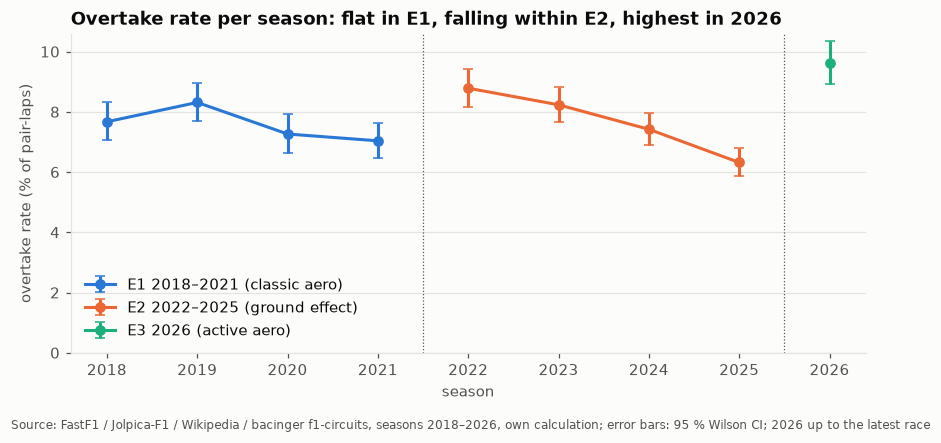

In [16]:
s = df.groupby(["season", "era"])["overtake"].agg(["sum", "size"]).reset_index()
s["rate"] = s["sum"] / s["size"]
s["low"], s["high"] = wilson_ci(s["sum"], s["size"])

fig, ax = plt.subplots(figsize=(8, 4))
for era, g in s.groupby("era"):
    ax.errorbar(g["season"].to_numpy(), 100 * g["rate"].to_numpy(),
                yerr=[100 * (g["rate"] - g["low"]).to_numpy(),
                      100 * (g["high"] - g["rate"]).to_numpy()],
                fmt="o-", color=ERA_COLORS[era], capsize=3, label=ERA_LABELS[era])
for boundary in (2021.5, 2025.5):
    ax.axvline(boundary, color=TEXT_SECONDARY, linewidth=0.8, linestyle=":")
ax.set_xticks(sorted(df["season"].unique()))
ax.set_ylim(0, None)
ax.set_xlabel("season")
ax.set_ylabel("overtake rate (% of pair-laps)")
ax.set_title("Overtake rate per season: flat in E1, falling within E2, highest in 2026")
ax.legend(loc="lower left")
add_source(fig, SOURCE + "; error bars: 95 % Wilson CI; 2026 up to the latest race")
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "eda_rate_by_season")
plt.show()

### 3.2 How close do the cars follow? Gap at lap start per era

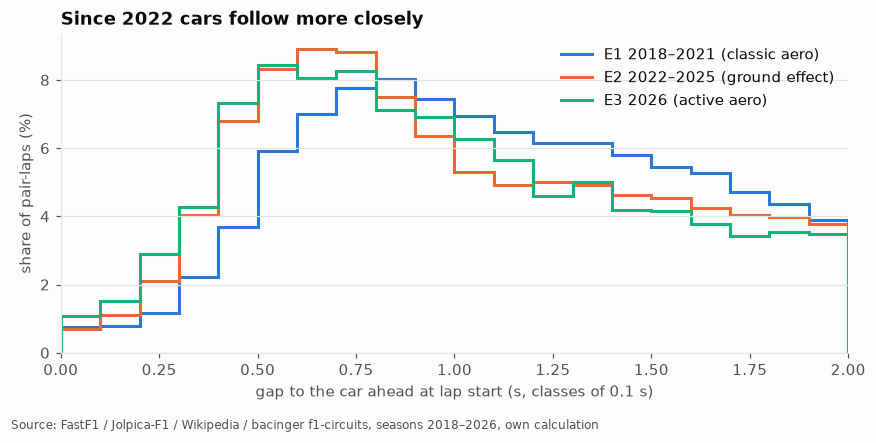

In [17]:
bins = np.arange(0, 2.0001, 0.1)
fig, ax = plt.subplots(figsize=(8, 4))
for era, g in df.groupby("era"):
    share, _ = np.histogram(g["gap_s"], bins=bins)
    ax.stairs(100 * share / share.sum(), bins, color=ERA_COLORS[era], linewidth=2,
              label=ERA_LABELS[era])
ax.set_xlim(0, 2)
ax.set_xlabel("gap to the car ahead at lap start (s, classes of 0.1 s)")
ax.set_ylabel("share of pair-laps (%)")
ax.set_title("Since 2022 cars follow more closely")
ax.legend()
add_source(fig, SOURCE)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "eda_gap_distribution_era")
plt.show()

### 3.3 Gap × tyre age difference (heatmap)

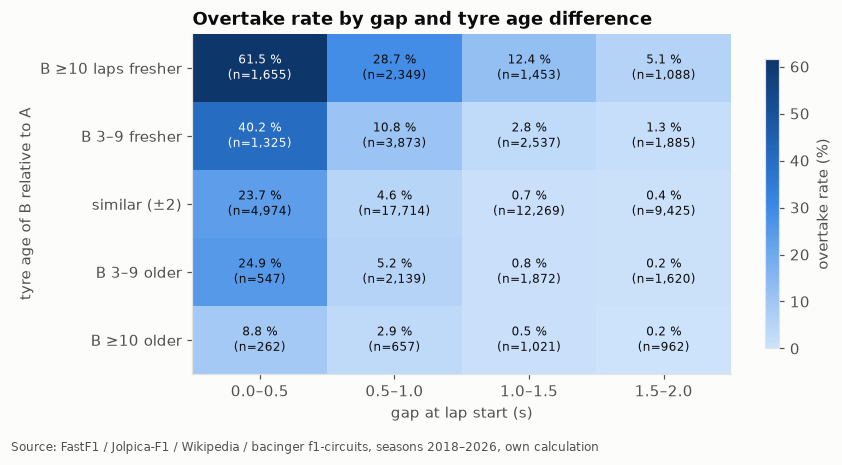

In [18]:
gap_cls = pd.cut(df["gap_s"], [0, 0.5, 1.0, 1.5, 2.0], include_lowest=True)
tyre_cls = pd.cut(df["tyre_age_diff"], [-100, -10, -3, 2, 9, 100],
                  labels=["B ≥10 laps fresher", "B 3–9 fresher", "similar (±2)",
                          "B 3–9 older", "B ≥10 older"])
heat = df.assign(gap_cls=gap_cls, tyre_cls=tyre_cls).pivot_table(
    index="tyre_cls", columns="gap_cls", values="overtake", aggfunc=["mean", "size"],
    observed=False)
rate, n = 100 * heat["mean"], heat["size"]

fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(rate.values, cmap=SEQUENTIAL, aspect="auto", vmin=0)
ax.set_xticks(range(rate.shape[1]), [f"{max(c.left, 0):.1f}–{c.right:.1f}" for c in rate.columns])
ax.set_yticks(range(rate.shape[0]), rate.index)
ax.grid(False)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        v = rate.values[i, j]
        ax.text(j, i, f"{v:.1f} %\n(n={n.values[i, j]:,})", ha="center", va="center",
                fontsize=8, color="white" if v > 0.6 * np.nanmax(rate.values) else "#0b0b0b")
ax.set_xlabel("gap at lap start (s)")
ax.set_ylabel("tyre age of B relative to A")
ax.set_title("Overtake rate by gap and tyre age difference")
fig.colorbar(im, ax=ax, label="overtake rate (%)", shrink=0.85)
add_source(fig, SOURCE)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "eda_heatmap_gap_tyre")
plt.show()

### 3.4 Overtakes per race by era

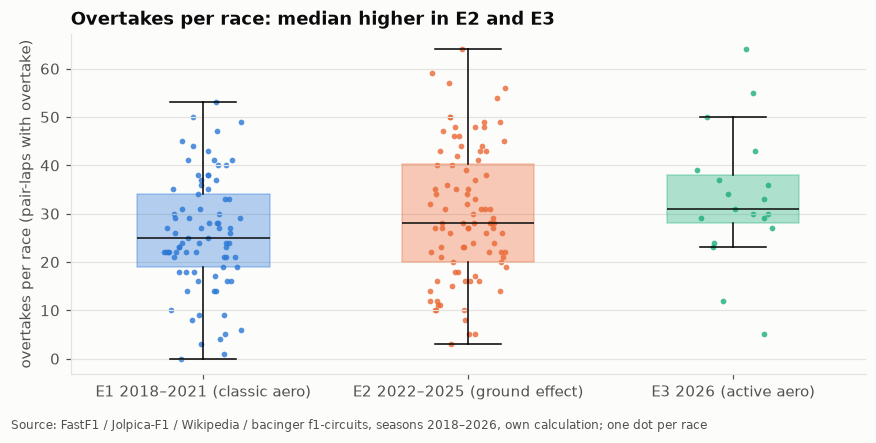

,count,mean,std,min,25%,50%,75%,max
era,,,,,,,,
E1,81.0,25.8,11.8,0.0,19.0,25.0,34.0,53.0
E2,92.0,29.8,13.8,3.0,20.0,28.0,40.2,64.0
E3,19.0,33.2,13.7,5.0,28.0,31.0,38.0,64.0


In [19]:
per_race = df.groupby(["era", "race_id"])["overtake"].sum().reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
eras = sorted(per_race["era"].unique())
data = [per_race.loc[per_race["era"] == e, "overtake"] for e in eras]
box = ax.boxplot(data, positions=range(len(eras)), widths=0.5, patch_artist=True,
                 showfliers=False, medianprops={"color": "#0b0b0b"})
for patch, era in zip(box["boxes"], eras):
    patch.set_facecolor(ERA_COLORS[era]); patch.set_alpha(0.35); patch.set_edgecolor(ERA_COLORS[era])
rng = np.random.default_rng(42)
for i, (era, values) in enumerate(zip(eras, data)):
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(values)), values, s=14,
               color=ERA_COLORS[era], alpha=0.8, linewidths=0)
ax.set_xticks(range(len(eras)), [ERA_LABELS[e] for e in eras])
ax.set_ylabel("overtakes per race (pair-laps with overtake)")
ax.set_title("Overtakes per race: median higher in E2 and E3")
add_source(fig, SOURCE + "; one dot per race")
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "eda_overtakes_per_race_era")
plt.show()
per_race.groupby("era")["overtake"].describe().round(1)

### 3.5 Distributions of the race-situation features

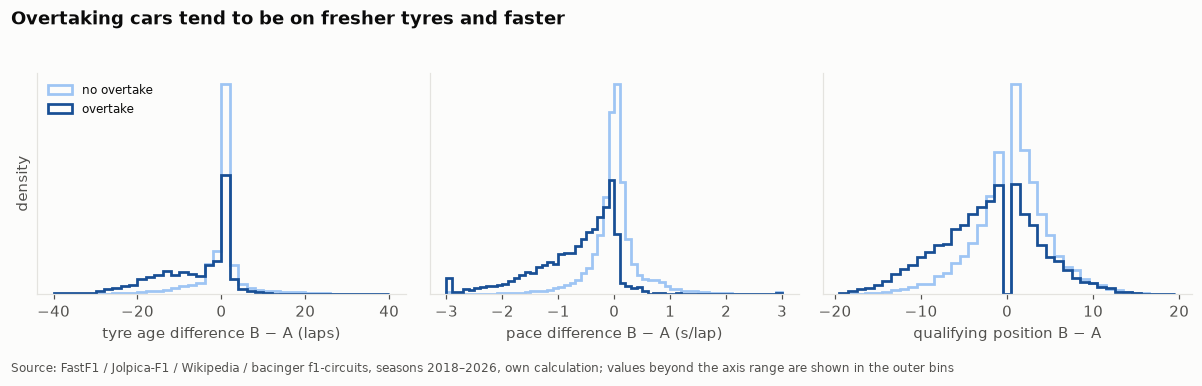

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
specs = [("tyre_age_diff", np.arange(-40, 41, 2), "tyre age difference B − A (laps)"),
         ("pace_diff", np.arange(-3, 3.01, 0.1), "pace difference B − A (s/lap)"),
         ("quali_gap", np.arange(-19.5, 20, 1), "qualifying position B − A")]
for ax, (col, b, label) in zip(axes, specs):
    for target, color, name in ((0, "#9ec5f4", "no overtake"), (1, "#184f95", "overtake")):
        values = df.loc[df["overtake"] == target, col].dropna()
        ax.hist(values.clip(b[0], b[-1]), bins=b, density=True, histtype="step",
                linewidth=1.8, color=color, label=name)
    ax.set_xlabel(label)
    ax.set_yticks([])
axes[0].set_ylabel("density")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Overtaking cars tend to be on fresher tyres and faster", x=0.01, ha="left",
             fontweight="bold")
add_source(fig, SOURCE + "; values beyond the axis range are shown in the outer bins")
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
save(fig, "eda_feature_distributions")
plt.show()

### 3.6 Correlation matrix (Spearman)

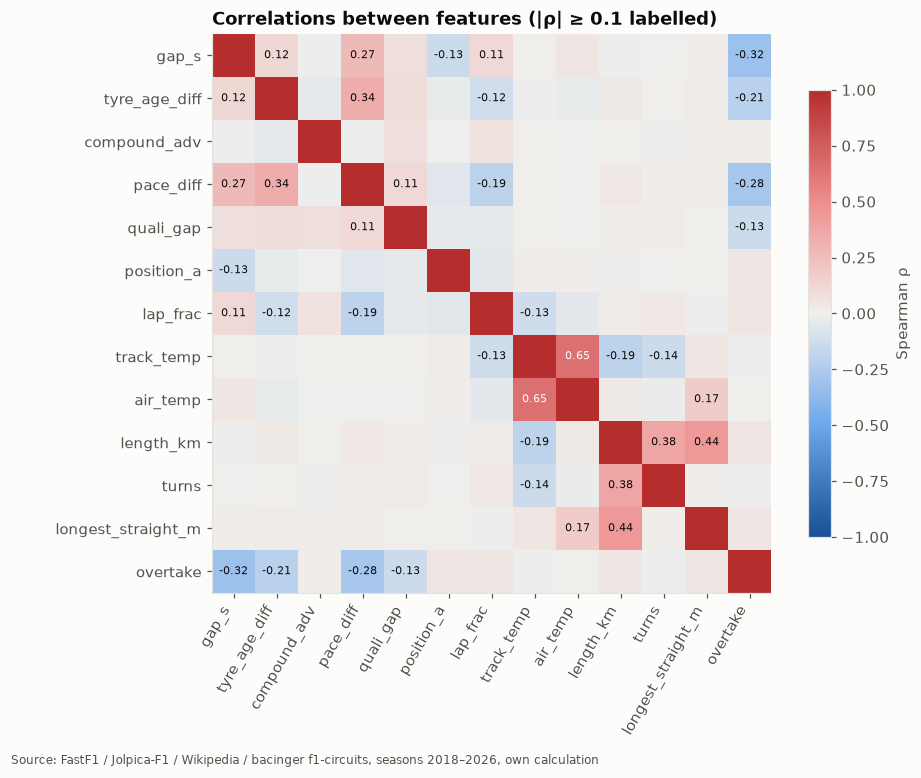

In [21]:
corr = df[NUMERIC + ["overtake"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if i != j and abs(corr.values[i, j]) >= 0.1:
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(corr.values[i, j]) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, label="Spearman ρ", shrink=0.8)
ax.set_title("Correlations between features (|ρ| ≥ 0.1 labelled)")
add_source(fig, SOURCE)
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "eda_correlation")
plt.show()

Strongly related feature pairs (e.g. air and track temperature, circuit length and number of turns) are relevant for the logistic regression (multicollinearity); the modelling notebook checks the variance inflation factors.

### 3.7 Circuits: overtake rate vs. longest straight (GeoJSON)

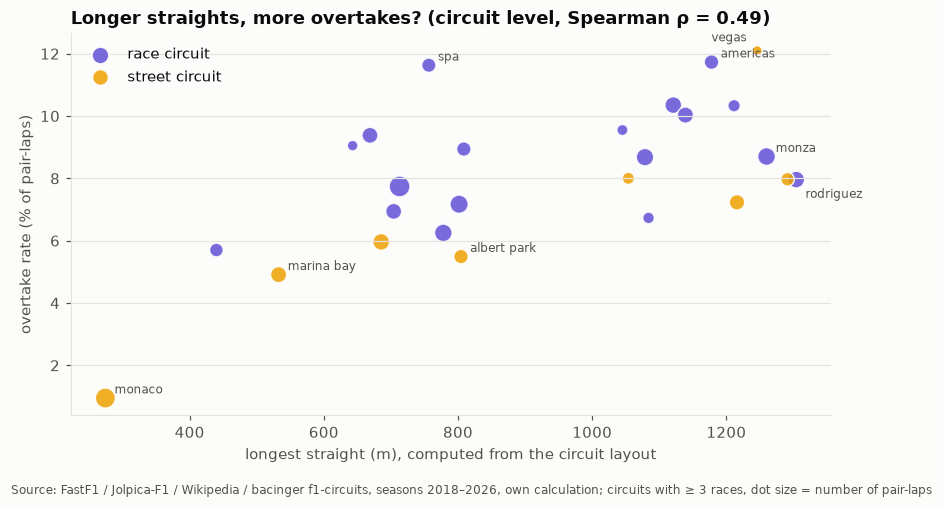

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for ctype, g in circuits.groupby("circuit_type"):
    ax.scatter(g["longest_straight_m"], g["rate_pct"], s=g["pair_laps"] / 25,
               color=CIRCUIT_TYPE_COLORS[ctype], alpha=0.85, label=f"{ctype} circuit",
               edgecolors="white", linewidths=1)
LABELS = {"monaco": (6, 3), "marina_bay": (6, 3), "albert_park": (6, 3), "spa": (6, 3),
          "americas": (6, 3), "vegas": (-30, 6), "monza": (6, 3), "rodriguez": (6, -12)}
for _, r in circuits.iterrows():
    if r["circuit_id"] in LABELS:
        ax.annotate(r["circuit_id"].replace("_", " "), (r["longest_straight_m"], r["rate_pct"]),
                    xytext=LABELS[r["circuit_id"]], textcoords="offset points", fontsize=8,
                    color=TEXT_SECONDARY)
rho = circuits[["longest_straight_m", "rate_pct"]].corr(method="spearman").iloc[0, 1]
ax.set_xlabel("longest straight (m), computed from the circuit layout")
ax.set_ylabel("overtake rate (% of pair-laps)")
ax.set_title(f"Longer straights, more overtakes? (circuit level, Spearman ρ = {rho:.2f})")
ax.legend(loc="upper left")
add_source(fig, SOURCE + "; circuits with ≥ 3 races, dot size = number of pair-laps")
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "eda_circuit_straight")
plt.show()

### 3.8 Special case: wet races

In [23]:
wet_races = df.groupby(["season", "round", "circuit"]).agg(
    wet_share=("wet_tyres", "mean"), pair_laps=("overtake", "size"),
    rate=("overtake", "mean")).query("wet_share > 0.3")
wet_races["rate_pct"] = (100 * wet_races.pop("rate")).round(2)
wet_races["wet_share"] = (100 * wet_races["wet_share"]).round(0)
wet_races.sort_values("wet_share", ascending=False)

wet_share  pair_laps  rate_pct
season round circuit                                                       
2020   14    Istanbul Park                       100.0        210     11.43
2022   18    Suzuka Circuit                      100.0        167      6.59
2021   16    Istanbul Park                       100.0        333      6.61
2024   21    Autódromo José Carlos Pace          100.0        465      5.59
2025   1     Albert Park Grand Prix Circuit       92.0        197      6.09
       12    Silverstone Circuit                  81.0        199      8.04
2024   9     Circuit Gilles Villeneuve            72.0        556      6.29
2022   17    Marina Bay Street Circuit            71.0        248      4.03
2019   11    Hockenheimring                       55.0        208     13.94
2021   2     Autodromo Enzo e Dino Ferrari        35.0        336      8.33
2022   4     Autodromo Enzo e Dino Ferrari        31.0        376      3.72

Races in which more than 30 % of the pair-laps were driven on intermediate or wet tyres. They are kept in the dataset with `wet_tyres` as a feature; the models are additionally checked without them (robustness).